# Fitting hyperparameters

The lengthscale and measurement variance affect how a GP explains our data.
A short lengthscale allows rapid changes in the function. A large measurement
variance allows more of the variation in the observations to be attributed
to measurement error. How can we choose these settings from data, and when
does prior knowledge change the answer?

We'll fit a GP to fifteen noisy measurements of a sine function. We know the
underlying function in this synthetic example, so we can compare our predictions
with it. The fitting procedure sees only the measurements.

In [1]:
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

from gpex import (
    FunctionalBlock,
    FunctionalDataset,
    FunctionalQuery,
    GaussianProcess,
    ObservationBlock,
    kernels,
    operators,
)

x_observed = jnp.linspace(-1.5, 1.5, 15)[:, None]
y_observed = jnp.sin(2.0 * x_observed[:, 0]) + jnp.sqrt(0.02) * jax.random.normal(
    jax.random.key(3), (15,)
)

## Choose what to fit

We'll fit the RBF lengthscale and the measurement-error variance shared by all
fifteen observations. The kernel variance stays at `1.0`, giving function values
a prior scale of order one.

Wrapping a value in `PositiveParameter` makes it trainable and keeps it
positive. Ordinary numbers and arrays stay fixed. The initial values below
are starting points for optimization, not constraints on the fitted values.

For the MAP fit, suppose previous experiments suggest a lengthscale around
`0.5`, and instrument calibration suggests a measurement variance around
`0.02`. We'll express this knowledge using log-normal priors. Each prior's
`log_mean` is the logarithm of its median, and `log_standard_deviation` controls
its spread. These choices leave room for the data to change our estimates:

| Quantity | Prior median | Approximate central 95% prior range |
| --- | ---: | ---: |
| Lengthscale, in location units | 0.5 | 0.25–1.0 |
| Measurement variance, in squared function-value units | 0.02 | 0.0075–0.053 |

MAP requires a prior for every explicit `Parameter`. We'll attach them now,
but the likelihood-only fit will ignore them.

In [2]:
from math import log

from gpex.parameters import PositiveParameter
from gpex.parameters.priors import LogNormalPrior

gp = GaussianProcess(
    kernels.RBFKernel(
        variance=1.0,
        lengthscale=PositiveParameter(
            0.25,
            prior=LogNormalPrior(
                log_mean=log(0.5), log_standard_deviation=0.35,
            ),
            name="lengthscale",
        ),
    )
)

The measurement variance belongs to the dataset. Including both the GP and
the dataset in `initial_model` lets the optimizer fit both quantities.

In [3]:
dataset = FunctionalDataset([
    ObservationBlock.from_arrays(
        x_observed, y_observed,
        variance=PositiveParameter(
            0.08,
            prior=LogNormalPrior(
                log_mean=log(0.02), log_standard_deviation=0.5,
            ),
            name="measurement_variance",
        ),
        name="observed_values",
        max_size=15,
    )
])
initial_model = (gp, dataset)

## Look at the starting prediction

Before fitting, let's see what the initial lengthscale `0.25` and measurement
variance `0.08` imply. As in [First posterior](first-posterior.ipynb), an identity
query asks for function values, and `predict_marginals` supplies the means and
variances for a pointwise 95% interval.

In [4]:
x_plot = jnp.linspace(-2.0, 2.0, 151)[:, None]
query = FunctionalQuery([
    FunctionalBlock(x_plot, operators.Identity(), name="function")
])
initial_prediction = gp.condition(dataset).predict_marginals(query)

In [5]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.8),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})


def plot_prediction(ax, prediction, title):
    mean = prediction.mean["function"]
    sd = jnp.sqrt(prediction.variance["function"])
    ax.fill_between(
        x_plot[:, 0], mean - 1.96 * sd, mean + 1.96 * sd,
        color="#1F4E79", alpha=0.15, linewidth=0,
        label="95% posterior interval",
    )
    ax.plot(x_plot[:, 0], mean, color="#1F4E79", label="Posterior mean")
    ax.plot(
        x_plot[:, 0], jnp.sin(2.0 * x_plot[:, 0]),
        color="0.3", linestyle="--", linewidth=1.2,
        label="Underlying function",
    )
    ax.scatter(
        x_observed[:, 0], y_observed,
        color="#D97706", marker="x", s=40, zorder=3,
        label="Measurements",
    )
    ax.set(
        title=title, xlabel="Location", ylabel="Function value",
        ylim=(-2.1, 2.1),
    )

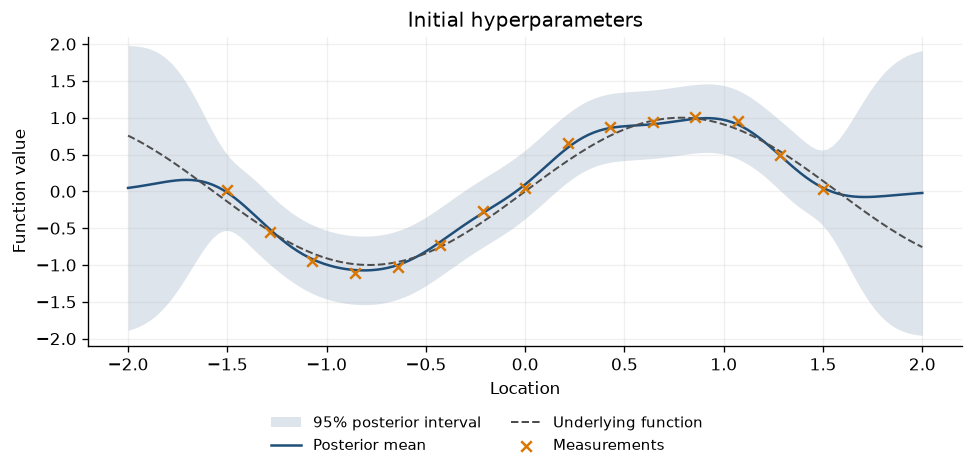

In [6]:
fig, ax = plt.subplots(layout="constrained")
plot_prediction(ax, initial_prediction, "Initial hyperparameters")
fig.legend(loc="outside lower center", ncol=2, frameon=False, fontsize=9)
plt.show()

## Fit by MLE and MAP

The short initial lengthscale lets the mean follow local fluctuations, while
the interval leaves considerable uncertainty between the observations and
outside their range. We'll now let the data inform these settings.

**Maximum marginal likelihood (MLE)** chooses hyperparameters that make the
observed values most probable after averaging over the unknown GP function.
**Maximum a posteriori estimation (MAP)** also uses the parameter priors we
specified above. It favors settings that explain the data and have high prior
density.

`fit_lbfgs` minimizes an objective, so we supply the negative log marginal
likelihood for MLE and the negative log posterior for MAP. Both fits use the
same starting model.

In [7]:
from gpex.fitting import (
    fit_lbfgs,
    negative_log_marginal_likelihood,
    negative_log_posterior,
)


def mle_objective(candidate):
    candidate_gp, candidate_data = candidate
    return negative_log_marginal_likelihood(candidate_gp, candidate_data)


def map_objective(candidate):
    candidate_gp, candidate_data = candidate
    return negative_log_posterior(candidate_gp, candidate_data)

In [8]:
mle_result = fit_lbfgs(
    initial_model, mle_objective,
    max_steps=100, gradient_tolerance=1e-5,
)
map_result = fit_lbfgs(
    initial_model, map_objective,
    max_steps=100, gradient_tolerance=1e-5,
)

Check convergence before interpreting the fitted parameters. `converged=True`
means the gradient norm reached the requested tolerance.

In [9]:
for name, result in (("MLE", mle_result), ("MAP", map_result)):
    print(
        f"{name}: converged={bool(result.converged)}, "
        f"updates={int(result.step_count)}, "
        f"gradient norm={float(result.gradient_norm):.2e}"
    )

MLE: converged=True, updates=10, gradient norm=4.67e-07
MAP: converged=True, updates=7, gradient norm=9.07e-07


Both fits meet the `1e-5` tolerance. This checks local convergence.

The result's `model` contains a fitted GP **and a fitted dataset**. We need both
for prediction because we trained the measurement variance as well as the
lengthscale. The original `gp` and `dataset` still hold their initial values.

In [10]:
mle_gp, mle_data = mle_result.model
map_gp, map_data = map_result.model

print(f"{'Model':<10} {'Lengthscale':>12} {'Measurement variance':>22}")
for name, fitted_gp, fitted_data in (
    ("Initial", gp, dataset),
    ("MLE", mle_gp, mle_data),
    ("MAP", map_gp, map_data),
):
    print(
        f"{name:<10} {float(fitted_gp.kernel.lengthscales.lengthscale):>12.3f} "
        f"{float(fitted_data.variance_flat[0]):>22.4f}"
    )

Model       Lengthscale   Measurement variance
Initial           0.250                 0.0800
MLE               0.777                 0.0053
MAP               0.689                 0.0099


## Compare the fitted predictions

Both fits increase the lengthscale and reduce the measurement variance. For
this sample, MLE estimates a measurement variance of about `0.0053`. MAP puts
it closer to our calibration prior, at about `0.0099`, and chooses a somewhat
shorter lengthscale than MLE.

Let's condition each fitted GP on its fitted dataset and compare the function
predictions on the same axes as before.

In [11]:
mle_prediction = mle_gp.condition(mle_data).predict_marginals(query)
map_prediction = map_gp.condition(map_data).predict_marginals(query)

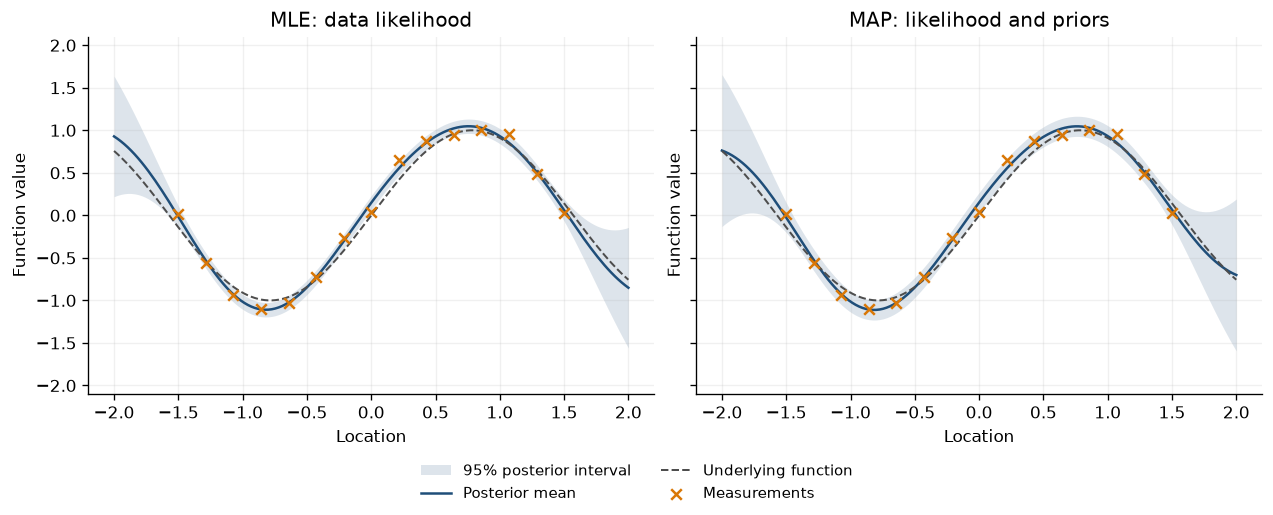

In [12]:
fig, axes = plt.subplots(
    1, 2, figsize=(10.5, 4.2), sharex=True, sharey=True,
    layout="constrained",
)
plot_prediction(axes[0], mle_prediction, "MLE: data likelihood")
plot_prediction(axes[1], map_prediction, "MAP: likelihood and priors")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center",
    ncol=2, frameon=False, fontsize=9,
)
plt.show()

The fitted means follow the broad rise and fall of the function, with much
narrower intervals through the observations than the initial prediction.
The MLE and MAP means are close in the observed region. MAP's larger
measurement variance leaves more uncertainty there, and its shorter
lengthscale lets uncertainty grow faster beyond the observations.

These are intervals for the underlying function, not for a future noisy
measurement. They condition on the fitted hyperparameters and do not include
uncertainty in those parameters.

The [fitting reference](../api/fitting.md) describes the returned diagnostics
and objective functions.